## Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Loading Dataset

In [4]:
data = pd.read_csv('train.csv')
data.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
converting dataframe into numpy array

In [5]:
data = np.array(data)
m,n = data.shape
m,n

(42000, 785)

In [6]:
np.random.shuffle(data)
data_dev = data[0:1000].T
x_dev = data_dev[1:n]
y_dev = data_dev[0]
x_dev = x_dev / 255.

data_train = data[1000:m].T
y_train = data_train[0]
x_train = data_train[1:n]

x_train = x_train/255.

In [7]:
y_train

array([0, 5, 4, ..., 1, 2, 7], dtype=int64)

In [8]:
x_train[:,0].shape

(784,)

In [ ]:
def init_params():
    w1 = np.random.rand(10,784) - 0.5
    b1 = np.random.rand(10,1) - 0.5
    w2 = np.random.rand(10,10) - 0.5
    b2 = np.random.rand(10,1) - 0.5
    return w1,b1,w2,b2

In [ ]:
def ReLU(z):
    return np.maximum(z, 0)

In [9]:
def forward_prop(w1,b1,w2,b2,x):
    z1 = w1.dot(x) + b1
    a1 = ReLU(z1)
    z2 = w2.dot(a1) + b2
    a2 = softmax(z2)
    return z1,a1,z2,a2
    
def one_hot(y):
    one_hot_y = np.zeros((y.size,y.max()+1))
    one_hot_y[np.arange(y.size), y] = 1
    one_hot_y = one_hot_y.T
    return one_hot_y

def deriv_relu(z):
    return z>0
    

def back_prop(z1,a1,z2,a2,w1,w2,x,y):
    m = y.size
    one_hot_y = one_hot(y)
    dz2 = a2 - one_hot_y
    dw2 = 1 / m  * dz2.dot(a1.T)
    #db2 = 1/m * np.sum(dz2,2)
    db2 = 1/m * np.sum(dz2)
    
    dz1 = w2.T.dot(dz2) * deriv_relu(z1)
    dw1 = 1/m * dz1.dot(x.T)
    #db1 = 1/m * np.sum(dz1,2)
    db1 = 1/m * np.sum(dz1)
    
    return dw1,db1,dw2,db2

def update_params(w1, b1, w2, b2, dw1, db1, dw2, db2, alpha):
    w1 = w1 - alpha * dw1
    b1 = b1 - alpha * db1
    
    w2 = w2 - alpha * dw2
    b2 = b2 - alpha * db2
    
    return w1,b1,w2,b2
    

In [10]:
def get_predictions(a2):
    return np.argmax(a2,0)

def get_accuracy(predictions,y):
    print(predictions,y)
    return np.sum(predictions == y)/y.size

def gradient_descent(x,y,iterations,alpha):
    w1,b1,w2,b2 = init_params()
    for i in range(0,iterations):
        z1,a1,z2,a2 = forward_prop(w1,b1,w2,b2,x)
        dw1,db1,dw2,db2 = back_prop(z1,a1,z2,a2,w1,w2,x,y)
        w1,b1,w2,b2 = update_params(w1,b1,w2,b2,dw1,db1,dw2,db2,alpha)
        if i % 10 == 0 :
            print('Iteration: ',i)
            print('Accuracy; ',get_accuracy(get_predictions(a2),y))
    return w1,b1,w2,b2
    

In [11]:
w1,b1,w2,b2 = gradient_descent(x_train,y_train,1001,0.1)

Iteration:  0
[4 4 4 ... 0 4 7] [0 5 4 ... 1 2 7]
Accuracy;  0.10426829268292682
Iteration:  10
[4 4 2 ... 0 7 7] [0 5 4 ... 1 2 7]
Accuracy;  0.1413170731707317
Iteration:  20
[4 4 2 ... 0 7 7] [0 5 4 ... 1 2 7]
Accuracy;  0.17834146341463414
Iteration:  30
[6 4 2 ... 0 7 7] [0 5 4 ... 1 2 7]
Accuracy;  0.22621951219512196
Iteration:  40
[6 4 6 ... 0 7 7] [0 5 4 ... 1 2 7]
Accuracy;  0.2840731707317073
Iteration:  50
[6 4 6 ... 3 6 4] [0 5 4 ... 1 2 7]
Accuracy;  0.3474634146341463
Iteration:  60
[6 1 6 ... 3 6 7] [0 5 4 ... 1 2 7]
Accuracy;  0.4156341463414634
Iteration:  70
[6 1 6 ... 1 6 7] [0 5 4 ... 1 2 7]
Accuracy;  0.471
Iteration:  80
[6 1 6 ... 1 6 7] [0 5 4 ... 1 2 7]
Accuracy;  0.5159268292682927
Iteration:  90
[6 1 6 ... 1 6 7] [0 5 4 ... 1 2 7]
Accuracy;  0.551
Iteration:  100
[6 9 4 ... 1 6 7] [0 5 4 ... 1 2 7]
Accuracy;  0.5773658536585365
Iteration:  110
[6 9 4 ... 1 6 7] [0 5 4 ... 1 2 7]
Accuracy;  0.5997317073170731
Iteration:  120
[6 9 4 ... 1 6 7] [0 5 4 ... 1 2 7

In [16]:
def make_predictions(x, w1, b1, w2, b2):
    _, _, _, A2 = forward_prop(w1, b1, w2, b2, x)
    predictions = get_predictions(A2)
    return predictions

def test_prediction(index, W1, b1, W2, b2):
    current_image = x_train[:, index, None]
    prediction = make_predictions(x_train[:, index, None], W1, b1, W2, b2)
    label = y_train[index]
    print("Prediction: ", prediction)
    print("Label: ", label)
    
    current_image = current_image.reshape((28, 28)) * 255
    plt.gray()
    plt.imshow(current_image, interpolation='nearest')
    plt.show()

Prediction:  [0]
Label:  0


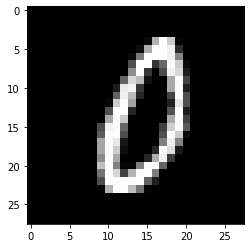

Prediction:  [5]
Label:  5


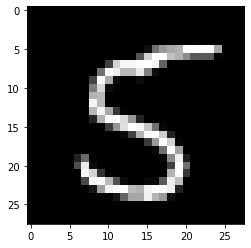

Prediction:  [4]
Label:  4


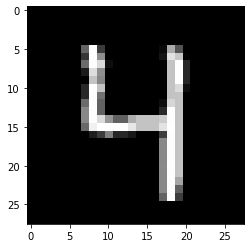

Prediction:  [9]
Label:  9


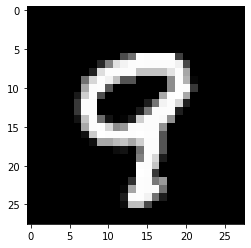

In [17]:
test_prediction(0, w1, b1, w2, b2)
test_prediction(1, w1, b1, w2, b2)
test_prediction(2, w1, b1, w2, b2)
test_prediction(3, w1, b1, w2, b2)